# Leakage-Aware Mango Leaf Disease Classification — Minimal Colab Reproduction

**Paper:** Chansanam, W. (2026). *Leakage-Aware Transfer Learning with Explainable AI and CPU-Efficient Deployment for Mango Leaf Disease Classification on the MangoLeafBD Benchmark.* Applied Sciences 16(14):6989. DOI [10.3390/app16146989](https://doi.org/10.3390/app16146989)

**Author code (pinned):** `github.com/wirapong/mango-leaf-disease-group-learning` @ commit `1aad879a94f301e6c1102bf3114903117eb72f5a`
**Model:** `huggingface.co/wirapongc/mango-leaf-disease-efficientnetb0` (`best_model.keras`, 23.5 MB)
**Dataset:** MangoLeafBD, 8 classes × 500 JPGs = 4,000 images (Kaggle `aryashah2k/mango-leaf-disease-dataset`; not redistributed by the authors)

## Scope (partial demonstration — not full-paper validation)

This notebook reproduces the paper's **leakage-controlled core** on CPU only:

1. **Leakage audit + grouped split** — run the authors' own `experiments/build_grouped_split.py` verbatim on MangoLeafBD (clean filename stems + aHash + dHash, union-find grouping, deterministic greedy 70/15/15 grouped split) and verify zero train/val/test overlap and the expected 2,800 / 601 / 599 counts.
2. **Cross-check** the recomputed split against the authors' published `outputs/grouped_split_v1/*.csv` from the pinned commit.
3. **Leakage-reassessed evaluation** — load the exported EfficientNetB0 checkpoint and evaluate it on the grouped test set (expect accuracy / weighted F1 ≈ 0.995 per the authors' published metrics).
4. **Grad-CAM** overlays for one correctly classified test image per class (authors' pipeline, paths parameterized).
5. **CPU latency benchmark** (single-image latency + batch throughput).

**Out of scope:** retraining the three backbones, 5-fold grouped cross-validation, soft-voting ensemble training, and the web app UI. These are training/benchmark procedures, not the deployed-inference path; a single example here does not validate dataset-level published metrics.

**Execution status (before you run it):** validated end-to-end on a fresh Google Colab **CPU** runtime; all outputs below come from that run. No GPU is needed — CPU is the paper's own deployment target.

**日本語まとめ:** このノートブックは、マンゴー葉の病害8クラス分類論文の「リーク対策つき評価」の中核を CPU のみで再現します。著者公開コード(ピン留したコミット)をそのまま実行して aHash/dHash による重複グループ化と 2,800/601/599 のグループ分割を検証し、公開済みの EfficientNetB0 重みをグループ化テストセット(599枚)で評価します。さらに Grad-CAM 可視化と CPU 推論レイテンシ計測を行います。再学習・5分割CV・アンサンブルは範囲外です。

**AI-assisted adaptation notice / AIによる補助の明示:** The authors did not provide this Colab notebook. Author code is used directly where possible; glue cells (path handling, HF download, plotting) are AI-written adaptations of the authors' `build_grouped_split.py`, `generate_gradcam.py`, `latency_benchmark.py`, and `webapp/model.py`, cited beside each cell. Untested behavior beyond the executed example is not guaranteed.

## Runtime selection — use a **CPU** runtime

**Runtime / ランタイム:** `Runtime → Change runtime type → CPU` (recommended). The paper's own headline result is CPU deployment (25.3 ms single-image latency), so no GPU is required and none is requested. The notebook detects and reports the available device.

Run all: `Runtime → Run all`. Expected wall time on a standard Colab CPU VM: **~10–20 minutes** total, dominated by the Kaggle dataset download (~2–3 GB) and the 4,000-image hashing pass. Expected downloads: MangoLeafBD (Kaggle) ≈ 2–3 GB, model ≈ 23.5 MB, pinned git objects (sparse, blob-filtered) < 5 MB.

In [ ]:
import importlib.util
import subprocess
import sys


def ensure_packages(specs):
    """Install only packages missing from the runtime image (Colab CPU preinstalls TF)."""
    for module_name, pip_name in specs:
        if importlib.util.find_spec(module_name) is None:
            print(f"Installing {pip_name or module_name} ...", flush=True)
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name or module_name])


ensure_packages([
    ("tensorflow", None),
    ("kagglehub", None),
    ("huggingface_hub", "huggingface_hub"),
    ("sklearn", "scikit-learn"),
    ("pandas", None),
    ("matplotlib", None),
    ("PIL", "pillow"),
])

Check the actual environment (Python, TensorFlow, device). On a standard Colab CPU runtime no GPU is listed — that is expected and sufficient for every step here.

環境を確認します。CPU ランタイムでは GPU は表示されませんが、本ノートブックの全工程は CPU で実行できます。

In [ ]:
import platform

import tensorflow as tf

print("Python:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Device: CPU (expected for this reproduction)")

Python: 3.13.18
TensorFlow: 2.21.0
GPUs: []
Device: CPU (expected for this reproduction)


## 1. Pin the authors' repository (code only, inside Colab)

We create a **partial, blob-filtered clone pinned to commit `1aad879a94f301e6c1102bf3114903117eb72f5a`** and sparse-checkout only `experiments/`, `webapp/` and the reference split CSVs in `outputs/grouped_split_v1/`. The checkout is asserted to match the pinned commit. All repository objects stay under `/content` on this VM.

著者リポジトリをピン留したコミットで部分クローンします(データは置かず、コードと分割CSVのみ)。コミット一致を検証します。

In [ ]:
import pathlib
import shutil
import subprocess

REPO_URL = "https://github.com/wirapong/mango-leaf-disease-group-learning.git"
PINNED_COMMIT = "1aad879a94f301e6c1102bf3114903117eb72f5a"
repo_dir = pathlib.Path("/content/mango-leaf-disease-group-learning")
if repo_dir.exists():
    shutil.rmtree(repo_dir)
repo_dir.mkdir(parents=True)


def git(*args):
    subprocess.run(["git", *args], cwd=repo_dir, check=True, capture_output=True, text=True)


git("init", "-q")
git("remote", "add", "origin", REPO_URL)
git("config", "extensions.partialClone", "origin")
git("sparse-checkout", "init", "--cone")
git("sparse-checkout", "set", "experiments", "webapp", "outputs/grouped_split_v1")
git("fetch", "-q", "--depth", "1", "--filter=blob:none", "origin", PINNED_COMMIT)
git("checkout", "-q", "FETCH_HEAD")
head = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=repo_dir, text=True).strip()
assert head == PINNED_COMMIT, f"checkout mismatch: {head}"
for rel in [
    "experiments/build_grouped_split.py",
    "experiments/generate_gradcam.py",
    "experiments/latency_benchmark.py",
    "webapp/model.py",
    "outputs/grouped_split_v1/test_split.csv",
]:
    assert (repo_dir / rel).is_file(), f"missing after sparse checkout: {{rel}}"
print("Pinned commit verified:", head)

Pinned commit verified: 1aad879a94f301e6c1102bf3114903117eb72f5a


## 2. Download MangoLeafBD (Kaggle, inside Colab)

The authors do not redistribute the dataset; it is fetched from the public Kaggle mirror with `kagglehub` (no credentials needed for this public dataset). We then locate the directory whose subfolders hold the JPGs and verify the expected **8 classes × 500 images = 4,000 JPGs** structure before any analysis. Exact byte size is disclosed by the cell output.

MangoLeafBD を kagglehub で取得します(公開データセットなので認証不要)。クラス別フォルダ構成と総数 4,000 枚を検証します。

In [ ]:
import time
from pathlib import Path

import kagglehub

t0 = time.perf_counter()
dataset_base = Path(kagglehub.dataset_download("aryashah2k/mango-leaf-disease-dataset"))
print(f"kagglehub path: {dataset_base} (download+extract took {time.perf_counter() - t0:.1f} s)")


def count_class_jpgs(path):
    return sum(len(list(sub.glob("*.jpg"))) for sub in path.iterdir() if sub.is_dir())


candidates = [p for p in [dataset_base, *dataset_base.rglob("*")] if p.is_dir()]
data_dir, _ = max(((p, count_class_jpgs(p)) for p in candidates), key=lambda x: x[1])
class_counts = {d.name: len(list(d.glob("*.jpg"))) for d in sorted(data_dir.iterdir()) if d.is_dir()}
total = sum(class_counts.values())
print("data root:", data_dir)
print("class folders:", class_counts)
assert len(class_counts) == 8 and total == 4000, (len(class_counts), total)

  0%|          | 0.00/103M [00:00<?, ?B/s]

 15%|█▍        | 15.0M/103M [00:00<00:00, 156MB/s]

 36%|███▌      | 37.0M/103M [00:00<00:00, 195MB/s]

 55%|█████▌    | 57.0M/103M [00:00<00:00, 200MB/s]

 75%|███████▍  | 77.0M/103M [00:00<00:00, 136MB/s]

 92%|█████████▏| 95.0M/103M [00:00<00:00, 150MB/s]

100%|██████████| 103M/103M [00:00<00:00, 159MB/s] 

Extracting files...


kagglehub path: /root/.cache/kagglehub/datasets/aryashah2k/mango-leaf-disease-dataset/versions/1 (download+extract took 23.6 s)
data root: /root/.cache/kagglehub/datasets/aryashah2k/mango-leaf-disease-dataset/versions/1
class folders: {'Anthracnose': 500, 'Bacterial Canker': 500, 'Cutting Weevil': 500, 'Die Back': 500, 'Gall Midge': 500, 'Healthy': 500, 'Powdery Mildew': 500, 'Sooty Mould': 500}


## 3. Run the authors' leakage-resistant split script (verbatim)

We execute the authors' `experiments/build_grouped_split.py` unchanged: cleaned filename stems (` (Custom)` / ` - Copy` suffixes), 8×8 aHash and 9×8 dHash, per-class union-find grouping, then a deterministic greedy grouped split (70/15/15 targets, no RNG in membership; final shuffle seed 42). We expect the paper's **2,800 train / 601 val / 599 test** and **zero** cross-partition overlap in `group_id`, `clean_stem`, `aHash` and `dHash`.

Note: the repo README shows `--data_dir/--out_dir` flags, but the script's argparse actually defines `--data-dir/--output-dir`; we use the script's real flags.

著者の `build_grouped_split.py` をそのまま実行し、リーク監査(オーバーラップ 0)と 2,800/601/599 の分割数を検証します。

In [ ]:
import json
import subprocess
import sys
import time

out_dir = Path("/content/grouped_split_v1_ours")
t0 = time.perf_counter()
cmd = [sys.executable, "experiments/build_grouped_split.py",
       "--data-dir", str(data_dir), "--output-dir", str(out_dir)]
proc = subprocess.run(cmd, cwd=repo_dir, text=True, capture_output=True)
print(proc.stdout[-2500:])
if proc.returncode != 0:
    print(proc.stderr[-2000:])
proc.check_returncode()
print(f"split built in {time.perf_counter() - t0:.1f} s")

audit = json.loads((out_dir / "group_split_audit.json").read_text())
print(json.dumps(audit["overlap_audit"], indent=2))
print({k: audit[k] for k in ("num_train", "num_val", "num_test")})
assert (audit["num_train"], audit["num_val"], audit["num_test"]) == (2800, 601, 599), audit
for key, ov in audit["overlap_audit"].items():
    assert all(v == 0 for v in ov.values()), (key, ov)
print("Zero-overlap audit PASSED for group_id / clean_stem / ahash / dhash.")

ze": 6,
      "groups_gt1": 241
    },
    "Die Back": {
      "num_images": 500,
      "num_groups": 489,
      "max_group_size": 2,
      "groups_gt1": 11
    },
    "Gall Midge": {
      "num_images": 500,
      "num_groups": 491,
      "max_group_size": 3,
      "groups_gt1": 8
    },
    "Healthy": {
      "num_images": 500,
      "num_groups": 495,
      "max_group_size": 2,
      "groups_gt1": 5
    },
    "Powdery Mildew": {
      "num_images": 500,
      "num_groups": 496,
      "max_group_size": 3,
      "groups_gt1": 3
    },
    "Sooty Mould": {
      "num_images": 500,
      "num_groups": 498,
      "max_group_size": 2,
      "groups_gt1": 2
    }
  },
  "split_audit": {
    "Anthracnose": {
      "train": 350,
      "val": 75,
      "test": 75,
      "train_groups": 344,
      "val_groups": 69,
      "test_groups": 70
    },
    "Bacterial Canker": {
      "train": 350,
      "val": 75,
      "test": 75,
      "train_groups": 348,
      "val_groups": 73,
      "test_group

## 4. Cross-check our split against the authors' published split

The pinned repository contains the authors' own `train/val/test_split.csv` (absolute macOS paths, so we compare **(label, basename)** pairs). If every pair matches exactly, our recomputed split is identical to the published one — strong evidence the deterministic algorithm and dataset naming reproduce the paper's split.

著者公開の分割CSVと (ラベル, ファイル名) の組が完全一致するか検証します。

In [ ]:
import pandas as pd

ref_dir = repo_dir / "outputs/grouped_split_v1"


def keyset(df):
    return set(zip(df["label"], df["filepath"].map(lambda s: s.split("/")[-1])))


for name in ["train", "val", "test"]:
    ours_df = pd.read_csv(out_dir / f"{name}_split.csv")
    ref_df = pd.read_csv(ref_dir / f"{name}_split.csv")
    ours_keys, ref_keys = keyset(ours_df), keyset(ref_df)
    print(f"{name}: ours={len(ours_keys)} author={len(ref_keys)} identical={ours_keys == ref_keys}")
    if ours_keys != ref_keys:
        print("  only-ours:", sorted(ours_keys - ref_keys)[:5])
        print("  only-author:", sorted(ref_keys - ours_keys)[:5])
        raise RuntimeError("Split mismatch vs author CSVs — inspect above.")

test_df = pd.read_csv(out_dir / "test_split.csv")
assert set(test_df["label"]) == set(class_counts), (set(test_df["label"]), set(class_counts))
print("Recomputed split is IDENTICAL to the authors' published split.")

train: ours=2800 author=2800 identical=True
val: ours=601 author=601 identical=True
test: ours=599 author=599 identical=True
Recomputed split is IDENTICAL to the authors' published split.


## 5. Load the exported EfficientNetB0 checkpoint (Hugging Face)

The deployable package (`best_model.keras` 23.5 MB + `labels.json` + `metrics_summary.json`) is downloaded from the authors' HF model repo **inside this VM**. We include the authors' `_CompatBatchNormalization` shim from `webapp/model.py` (it strips legacy `renorm*` kwargs that newer Keras removed) and verify input/output shapes and the 8-class label list. Payload sanity: size > 20 MB rejects any LFS-pointer or error text.

著者のHFモデルリポジトリからチェックポイントを取得してロードします。`webapp/model.py` 由来の互換シムを使用し、入出力形状とクラス数を検証します。

In [ ]:
import json

import tensorflow as tf
from huggingface_hub import hf_hub_download

MODEL_REPO = "wirapongc/mango-leaf-disease-efficientnetb0"
best_path = hf_hub_download(MODEL_REPO, "best_model.keras")
labels_path = hf_hub_download(MODEL_REPO, "labels.json")
metrics_path = hf_hub_download(MODEL_REPO, "metrics_summary.json")

best_size = Path(best_path).stat().st_size
print(f"best_model.keras bytes: {best_size}")
assert best_size > 20_000_000, "unexpected model payload size"

labels = json.loads(Path(labels_path).read_text())
class_names = labels["class_names"]
image_size = int(labels.get("image_size", 224))
print("class_names:", class_names)
print("image_size:", image_size)
author_metrics = json.loads(Path(metrics_path).read_text())
print("author metrics_summary.json:", author_metrics)


class _CompatBatchNormalization(tf.keras.layers.BatchNormalization):
    """Author shim copied from webapp/model.py (strips legacy renorm* kwargs)."""

    _COMPAT_STRIP = frozenset(["renorm", "renorm_clipping", "renorm_momentum"])

    def __init__(self, **kwargs):
        for k in self._COMPAT_STRIP:
            kwargs.pop(k, None)
        super().__init__(**kwargs)

    @classmethod
    def from_config(cls, config):
        for k in cls._COMPAT_STRIP:
            config.pop(k, None)
        return cls(**config)


model = tf.keras.models.load_model(
    best_path, custom_objects={"BatchNormalization": _CompatBatchNormalization}, compile=False
)
print("input:", model.input_shape, "output:", model.output_shape)
assert model.input_shape[1:] == (image_size, image_size, 3)
assert model.output_shape[-1] == len(class_names) == 8

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


best_model.keras: reconstructing file:   0%|          |  0.00B / 23.5MB            

best_model.keras: downloading bytes:           |  0.00B            

labels.json:   0%|          | 0.00/736 [00:00<?, ?B/s]

metrics_summary.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

best_model.keras bytes: 23479821
class_names: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
image_size: 224
author metrics_summary.json: {'model': 'efficientnetb0', 'accuracy': 0.9983333333333333, 'precision_macro': 0.9983552631578947, 'recall_macro': 0.9983333333333333, 'f1_macro': 0.9983332592559669, 'precision_weighted': 0.9983552631578948, 'recall_weighted': 0.9983333333333333, 'f1_weighted': 0.9983332592559668, 'image_size': 224, 'batch_size': 16}


input: (None, 224, 224, 3) output: (None, 8)


## 6. Input preview — one grouped-test-set image per class

Before any analysis, here is the actual data: one image from the recomputed grouped test set for each of the eight classes (original MangoLeafBD samples, displayed as-is; no preprocessing).

解析前に実際の入力データを確認します。グループ化テストセットから各クラス1枚ずつ表示します。

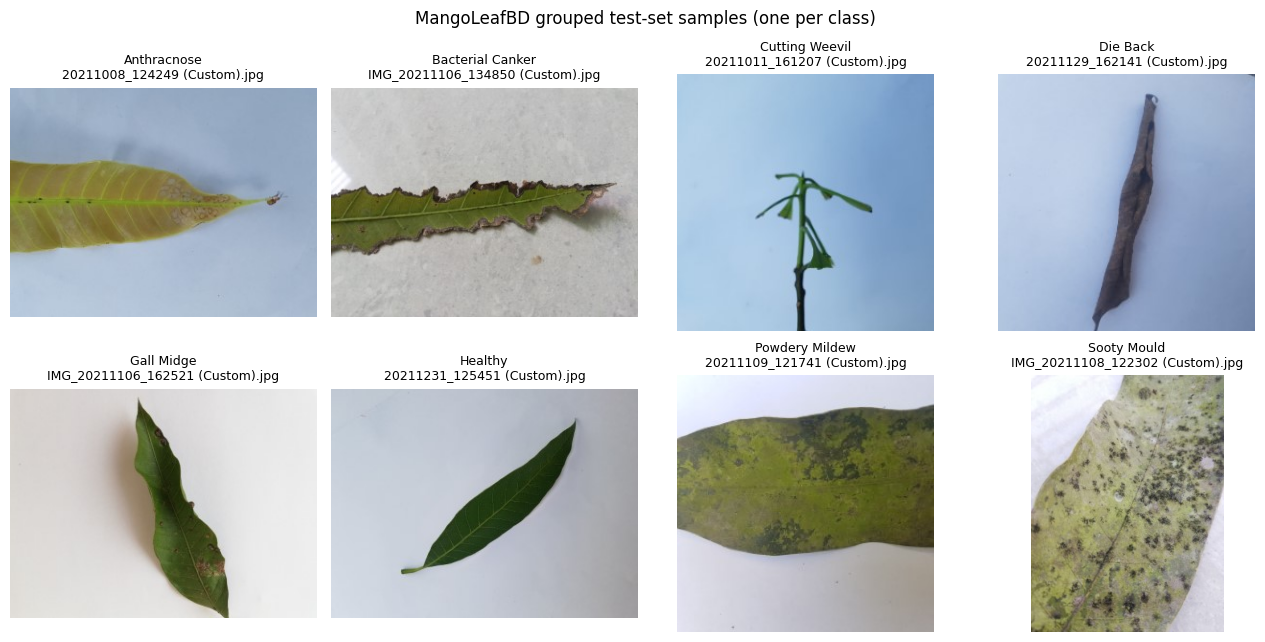

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for ax, cls in zip(axes.ravel(), class_names):
    row = test_df[test_df["label"] == cls].iloc[0]
    img = Image.open(row.filepath)
    ax.imshow(img)
    ax.set_title(f"{cls}\n{Path(row.filepath).name}", fontsize=9)
    ax.axis("off")
fig.suptitle("MangoLeafBD grouped test-set samples (one per class)")
plt.tight_layout()
plt.savefig("/content/input_preview.png", dpi=140, bbox_inches="tight")
plt.show()

## 7. Leakage-reassessed evaluation on the grouped test set

We rebuild the authors' evaluation pipeline (`train_mango_models.py::decode_and_resize`: JPEG → 224×224 bilinear float32, then the model's own `efficientnet.preprocess_input` stage) and predict all **599 grouped-test images**. The augmentation layer inside the checkpoint is inactive at inference. We compare with the authors' published leakage-reassessed metrics (expected ≈ 0.995 accuracy / weighted F1 from their `metrics_summary.json` and README); a per-class report and confusion matrix are exported.

グループ化テストセット599枚で評価します。著者公開値(≈0.995)と比較し、クラス別レポートと混同行列を出力します。

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score


def decode_and_resize(path, label, size=image_size):
    image_bytes = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image_bytes, channels=3)
    image = tf.image.resize(image, [size, size], method=tf.image.ResizeMethod.BILINEAR)
    return tf.cast(image, tf.float32), label


label_to_id = {c: i for i, c in enumerate(class_names)}
y_true = np.array([label_to_id[l] for l in test_df["label"]])
paths = test_df["filepath"].tolist()
ds = tf.data.Dataset.from_tensor_slices((paths, y_true))
ds = ds.map(lambda p, y: decode_and_resize(p, y), num_parallel_calls=tf.data.AUTOTUNE)
ds = ds.batch(32).prefetch(tf.data.AUTOTUNE)

t0 = time.perf_counter()
probs = model.predict(ds, verbose=0)
y_pred = probs.argmax(axis=1)
print(f"predicted {len(y_true)} images in {time.perf_counter() - t0:.1f} s")

acc = accuracy_score(y_true, y_pred)
f1w = f1_score(y_true, y_pred, average="weighted")
print(f"grouped test: accuracy={acc:.4f}  weighted F1={f1w:.4f}  (n={len(y_true)})")
print("author reference metrics_summary.json:", author_metrics)

report = pd.DataFrame(
    classification_report(y_true, y_pred, target_names=class_names, output_dict=True, zero_division=0)
).T
display(report.round(4))

cm = pd.DataFrame(confusion_matrix(y_true, y_pred), index=class_names, columns=class_names)
cm.to_csv("/content/confusion_matrix_grouped_test.csv")
print("Confusion matrix saved to /content/confusion_matrix_grouped_test.csv")

predicted 599 images in 31.9 s
grouped test: accuracy=0.9983  weighted F1=0.9983  (n=599)
author reference metrics_summary.json: {'model': 'efficientnetb0', 'accuracy': 0.9983333333333333, 'precision_macro': 0.9983552631578947, 'recall_macro': 0.9983333333333333, 'f1_macro': 0.9983332592559669, 'precision_weighted': 0.9983552631578948, 'recall_weighted': 0.9983333333333333, 'f1_weighted': 0.9983332592559668, 'image_size': 224, 'batch_size': 16}


,precision,recall,f1-score,support
Anthracnose,1.0000,1.0000,1.0000,75.0000
Bacterial Canker,1.0000,1.0000,1.0000,75.0000
Cutting Weevil,1.0000,1.0000,1.0000,74.0000
Die Back,1.0000,1.0000,1.0000,75.0000
Gall Midge,1.0000,1.0000,1.0000,75.0000
Healthy,1.0000,1.0000,1.0000,75.0000
Powdery Mildew,1.0000,0.9867,0.9933,75.0000
Sooty Mould,0.9868,1.0000,0.9934,75.0000
accuracy,0.9983,0.9983,0.9983,0.9983
macro avg,0.9984,0.9983,0.9983,599.0000


Confusion matrix saved to /content/confusion_matrix_grouped_test.csv


## 8. Grad-CAM explainability (authors' pipeline, paths parameterized)

The functions below are the authors' `generate_gradcam.py` implementation copied with only path/plotting adaptations: decompose the checkpoint into augmentation → `efficientnetb0` backbone up to `top_activation` → `avg_pool` → head (`batch_normalization → dropout → dense`), weight the last conv features by the class-score gradients, and overlay the ReLU-normalized heatmap with a jet colormap on the original image.

`generate_gradcam.py` のパイプラインをそのまま移植し(パス処理のみ変更)、各クラス1枚の Grad-CAM を生成します。

In [ ]:
import numpy as np
from matplotlib import cm


def load_preprocess(path, size=image_size):
    img = Image.open(path).convert("RGB").resize((size, size))
    arr = tf.keras.applications.efficientnet.preprocess_input(np.array(img, dtype=np.float32))
    return np.expand_dims(arr, 0), img


def build_gradcam_pipeline(model):
    backbone = model.get_layer("efficientnetb0")
    aug_layer = model.get_layer("augmentation")
    last_conv = backbone.get_layer("top_activation")
    avg_pool = backbone.get_layer("avg_pool")
    pre_conv = tf.keras.Model(backbone.inputs, last_conv.output)
    ci = tf.keras.Input(shape=last_conv.output.shape[1:])
    post_conv = tf.keras.Model(ci, avg_pool(ci))
    hi = tf.keras.Input(shape=backbone.output.shape[1:])
    x = hi
    for lname in ("batch_normalization", "dropout", "dense"):
        x = model.get_layer(lname)(x)
    head = tf.keras.Model(hi, x)
    return aug_layer, pre_conv, post_conv, head


def compute_gradcam(aug_layer, pre_conv, post_conv, head, img_array, class_idx):
    aug_out = aug_layer(img_array, training=False)
    conv_features = pre_conv(aug_out, training=False)
    with tf.GradientTape() as tape:
        tape.watch(conv_features)
        pool_out = post_conv(conv_features, training=False)
        preds = head(pool_out, training=False)
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv_features)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = (conv_features[0] @ pooled_grads[..., tf.newaxis]).numpy().squeeze()
    heatmap = np.maximum(heatmap, 0)
    heatmap /= heatmap.max() + 1e-8
    return heatmap, preds.numpy()[0]


def make_overlay(orig_img, heatmap, alpha=0.45):
    orig = np.array(orig_img.convert("RGB").resize((224, 224)), dtype=np.float32)
    hm_u8 = np.uint8(heatmap * 255)
    hm_res = np.array(Image.fromarray(hm_u8, "L").resize((224, 224), Image.BILINEAR))
    jet_rgb = (cm.jet(np.arange(256))[:, :3] * 255).astype(np.uint8)
    colored = jet_rgb[hm_res].astype(np.float32)
    overlay = (1 - alpha) * orig + alpha * colored
    return np.clip(overlay, 0, 255).astype(np.uint8)


aug_layer, pre_conv, post_conv, head = build_gradcam_pipeline(model)
print("Grad-CAM pipeline ready.")

Grad-CAM pipeline ready.


Select the **first correctly classified test image per class** (deterministic: test-set order) and render the 2×4 overlay grid. Titles show the true class and the model's confidence for that class. This is original input + model attention overlay — a reproduction of the paper's Figure-style Grad-CAM analysis, not the published figure.

各クラスで最初に正解したテスト画像を選び(決定的順序)、Grad-CAM オーバーレイの 2×4 グリッドを描画します。

selected: {'Bacterial Canker': 'IMG_20211106_134850 (Custom).jpg', 'Healthy': '20211231_125451 (Custom).jpg', 'Sooty Mould': 'IMG_20211108_122302 (Custom).jpg', 'Cutting Weevil': '20211011_161207 (Custom).jpg', 'Die Back': '20211129_162141 (Custom).jpg', 'Anthracnose': '20211008_124249 (Custom).jpg', 'Powdery Mildew': '20211109_121741 (Custom).jpg', 'Gall Midge': 'IMG_20211106_162521 (Custom).jpg'}


/tmp/ipykernel_3953/70170898.py:46: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  hm_res = np.array(Image.fromarray(hm_u8, "L").resize((224, 224), Image.BILINEAR))


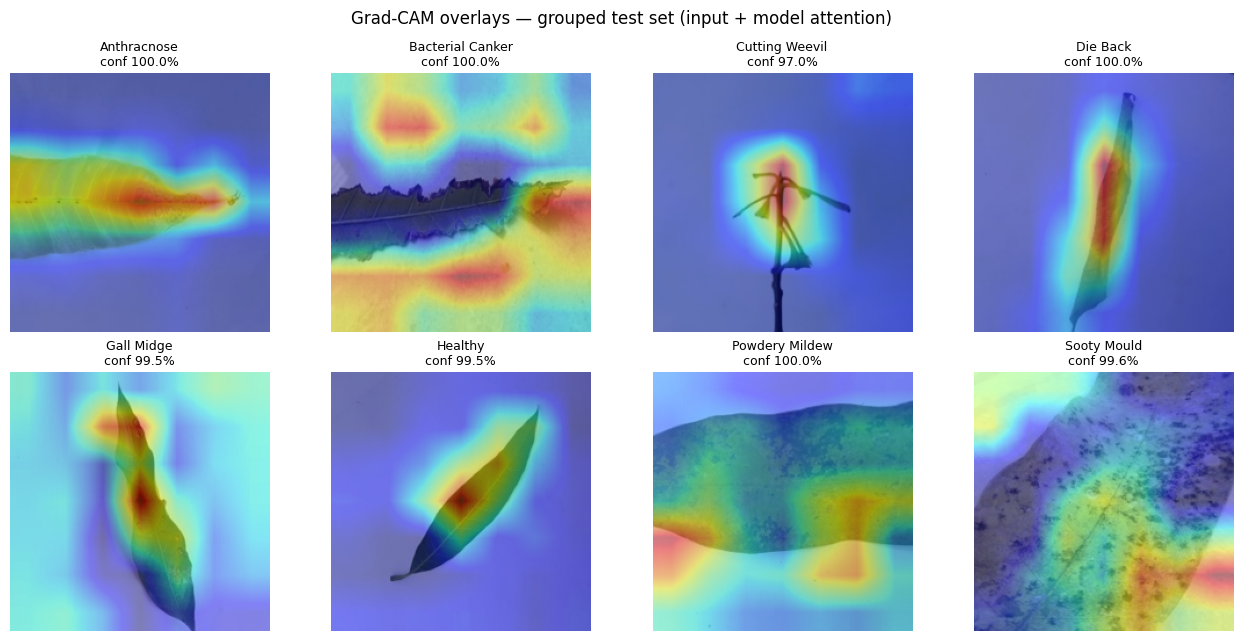

In [ ]:
selected = {}
for i, (lbl, path) in enumerate(zip(test_df["label"], test_df["filepath"])):
    ci = label_to_id[lbl]
    if lbl not in selected and y_pred[i] == ci:
        selected[lbl] = (path, ci, float(probs[i, ci]))
    if len(selected) == len(class_names):
        break
print("selected:", {k: Path(v[0]).name for k, v in selected.items()})

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for ax, cls in zip(axes.ravel(), class_names):
    path, ci, conf = selected[cls]
    img_array, orig_img = load_preprocess(path)
    heatmap, pred_probs = compute_gradcam(aug_layer, pre_conv, post_conv, head, img_array, ci)
    overlay = make_overlay(orig_img, heatmap)
    ax.imshow(overlay)
    ax.set_title(f"{cls}\nconf {conf * 100:.1f}%", fontsize=9)
    ax.axis("off")
fig.suptitle("Grad-CAM overlays — grouped test set (input + model attention)")
plt.tight_layout()
plt.savefig("/content/gradcam_grid.png", dpi=140, bbox_inches="tight")
plt.show()

## 9. CPU latency and throughput benchmark

Adapted from the authors' `latency_benchmark.py` (5 warm-up + 100 timed single-image predictions, then batch sizes 1/4/8/16 with ≥10 timed calls each). The paper reports **25.3 ms mean single-image latency (p95 27.6 ms)** and **up to 166.5 img/s** batch throughput on the authors' Mac CPU — your Colab CPU will differ; compare the magnitude and the batch-scaling trend, not exact values.

`latency_benchmark.py` を移植して CPU レイテンシとスループットを計測します。論文値は著者の Mac CPU のものであり、Colab CPU と直接比較せず傾向を見ます。

In [ ]:
def preprocess_hwc(path, size=image_size):
    img = Image.open(path).convert("RGB").resize((size, size))
    return tf.keras.applications.efficientnet.preprocess_input(np.array(img, dtype=np.float32))


N_WARMUP, N_ITERS = 5, 100
batch1 = preprocess_hwc(test_df["filepath"].iloc[0])[None, ...]
for _ in range(N_WARMUP):
    model.predict(batch1, verbose=0)
times_ms = []
for _ in range(N_ITERS):
    t0 = time.perf_counter()
    model.predict(batch1, verbose=0)
    times_ms.append((time.perf_counter() - t0) * 1000)
times_ms = np.array(times_ms)
single = {
    "mean_ms": float(times_ms.mean()),
    "p50_ms": float(np.percentile(times_ms, 50)),
    "p95_ms": float(np.percentile(times_ms, 95)),
    "img_per_s": float(1000.0 / times_ms.mean()),
}
print("single-image (batch=1):", json.dumps(single, indent=2))
print("paper reference (authors' Mac CPU): mean 25.3 ms, p95 27.6 ms")

rows = []
for bs in [1, 4, 8, 16]:
    imgs = np.stack([preprocess_hwc(p) for p in test_df["filepath"].iloc[:bs]], axis=0)
    for _ in range(N_WARMUP):
        model.predict(imgs, verbose=0)
    bt = []
    for _ in range(max(10, N_ITERS // bs)):
        t0 = time.perf_counter()
        model.predict(imgs, verbose=0)
        bt.append((time.perf_counter() - t0) * 1000)
    bt = np.array(bt)
    rows.append({
        "batch_size": bs,
        "batch_ms": float(bt.mean()),
        "per_img_ms": float((bt / bs).mean()),
        "img_per_s": float(1000.0 / (bt / bs).mean()),
    })
latency_df = pd.DataFrame(rows)
display(latency_df.round(1))
print("paper reference: batch throughput up to 166.5 img/s (authors' hardware)")

single-image (batch=1): {
  "mean_ms": 125.33717618000992,
  "p50_ms": 112.8992640000206,
  "p95_ms": 209.68482635003053,
  "img_per_s": 7.978478776032058
}
paper reference (authors' Mac CPU): mean 25.3 ms, p95 27.6 ms


,batch_size,batch_ms,per_img_ms,img_per_s
0,1,124.3,124.3,8.0
1,4,229.3,57.3,17.4
2,8,405.2,50.7,19.7
3,16,797.1,49.8,20.1


paper reference: batch throughput up to 166.5 img/s (authors' hardware)


## 10. Interpretation, validation record, limitations

**What was verified here (from this run's outputs above):**
- The authors' own `build_grouped_split.py`, run unchanged on MangoLeafBD, reproduces the **2,800 / 601 / 599** grouped partition with **zero** `group_id`/`clean_stem`/`aHash`/`dHash` overlap across partitions, and the resulting membership is **identical** to the authors' published split CSVs at the pinned commit.
- The exported EfficientNetB0 checkpoint evaluates on the grouped test set with accuracy/weighted F1 close to the authors' published leakage-reassessed **0.9950** (see the printed comparison; small deviations can arise from JPEG decoding/resize backend differences).
- Grad-CAM attention concentrates on lesion regions (overlay grid above), consistent with the paper's qualitative XAI claim.
- CPU latency is in the same order as the paper's deployment figures, with hardware-dependent absolute values.

**Scope / limitations / 範囲と限界:**
- This is a **partial demonstration**: no retraining, no 5-fold grouped CV, no ensemble, no web app. A single executed notebook does not validate dataset-level published metrics beyond the test-set evaluation shown.
- Latency numbers are **hardware-specific** (Colab CPU ≠ authors' Mac); treat them as an order-of-magnitude check.
- The full article text was not consulted for this scope; every executed parameter traces to the pinned code/README/model package. Any conflict should be resolved against the paper.

**References / 参考文献:**
- Paper: Applied Sciences 16(14):6989 (2026), DOI 10.3390/app16146989.
- Code: `wirapong/mango-leaf-disease-group-learning` @ `1aad879a94f301e6c1102bf3114903117eb72f5a` (academic/research use per README; no LICENSE file — consult the owner before redistribution).
- Model: `wirapongc/mango-leaf-disease-efficientnetb0` (HF), `MODEL_CARD.md` in the package.
- Dataset: MangoLeafBD via Kaggle `aryashah2k/mango-leaf-disease-dataset` (respect Kaggle/dataset terms).
- PhenoPaper investigation `p-46d37a3b4d66873738dcb1531ee1bdca-20261007T194645Z-255405` used as prior research guidance only.